In [10]:
import yfinance as yf
import pandas as pd
import numpy as np
from pathlib import Path

# Crear directorios si no existen
Path("../data/raw").mkdir(parents=True, exist_ok=True)
Path("../data/processed").mkdir(parents=True, exist_ok=True)

def generate_raw_data(start_date="2016-01-01", end_date="2026-01-01", save_path="../data/raw/raw_data.csv"):
    tickers = {"BTC": "BTC-USD", "SPY": "SPY", "VIX": "^VIX"}
    raw_dfs = []
    
    for name, ticker in tickers.items():
        df = yf.download(ticker, start=start_date, end=end_date)[['Open', 'High', 'Low', 'Close', 'Volume']]
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.droplevel(1)
        # Renombrar columnas para evitar colisiones
        df = df.add_prefix(f'{name}_')
        raw_dfs.append(df)
        
    # Unir todo utilizando el índice continuo de BTC (Outer join para ver todos los días, luego filtramos)
    # Usamos BTC_Close para garantizar que tenemos todos los días calendario
    df_raw = pd.concat(raw_dfs, axis=1)
    
    # Filtrar solo los días donde BTC operó (24/7)
    df_raw = df_raw.dropna(subset=['BTC_Close'])
    
    # Aplicar Forward Fill a los precios nominales de SPY y VIX durante los fines de semana
    df_raw = df_raw.ffill()
    
    df_raw.to_csv(save_path)
    print(f"Datos crudos guardados en: {save_path}")
    return df_raw

def process_data(raw_path="../data/raw/raw_data.csv", save_path="../data/processed/processed_data.csv"):
    df = pd.read_csv(raw_path, index_col='Date', parse_dates=True)
    
    processed = pd.DataFrame(index=df.index)
    
    # 1. Variables Endógenas BTC
    processed['BTC_r_oc'] = np.log(df['BTC_Close'] / df['BTC_Open'])
    processed['BTC_r_ho'] = np.log(df['BTC_High'] / df['BTC_Open'])
    processed['BTC_r_lo'] = np.log(df['BTC_Low'] / df['BTC_Open'])
    # Se reemplazan los ceros y NaNs en volumen para evitar -inf en el log
    vol_btc = df['BTC_Volume'].replace(0, np.nan).ffill()
    processed['BTC_r_vol'] = np.log(vol_btc / vol_btc.shift(1))
    
    # Target (r^2 t+1)
    btc_r_close = np.log(df['BTC_Close'] / df['BTC_Close'].shift(1))
    processed['target_r2_t1'] = (btc_r_close ** 2).shift(-1)
    
    # 2. Variables Exógenas SPY (Incluye los fines de semana matemáticamente nulos)
    processed['SPY_r_oc'] = np.log(df['SPY_Close'] / df['SPY_Open'])
    processed['SPY_r_ho'] = np.log(df['SPY_High'] / df['SPY_Open'])
    processed['SPY_r_lo'] = np.log(df['SPY_Low'] / df['SPY_Open'])
    vol_spy = df['SPY_Volume'].replace(0, np.nan).ffill()
    processed['SPY_r_vol'] = np.log(vol_spy / vol_spy.shift(1))
    processed['SPY_r_overnight'] = np.log(df['SPY_Open'] / df['SPY_Close'].shift(1))
    
    # 3. Variable Exógena VIX
    processed['VIX_log'] = np.log(df['VIX_Close'])
    
    # Eliminar NaNs generados por los shifts
    processed = processed.dropna()
    
    processed.to_csv(save_path)
    print(f"Datos procesados guardados en: {save_path}")
    return processed

# Ejecución
df_raw = generate_raw_data()
df_processed = process_data()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Datos crudos guardados en: ../data/raw/raw_data.csv
Datos procesados guardados en: ../data/processed/processed_data.csv


In [11]:
df_raw.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 3653 entries, 2016-01-01 to 2025-12-31
Freq: D
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   BTC_Open    3653 non-null   float64
 1   BTC_High    3653 non-null   float64
 2   BTC_Low     3653 non-null   float64
 3   BTC_Close   3653 non-null   float64
 4   BTC_Volume  3653 non-null   int64  
 5   SPY_Open    3650 non-null   float64
 6   SPY_High    3650 non-null   float64
 7   SPY_Low     3650 non-null   float64
 8   SPY_Close   3650 non-null   float64
 9   SPY_Volume  3650 non-null   float64
 10  VIX_Open    3650 non-null   float64
 11  VIX_High    3650 non-null   float64
 12  VIX_Low     3650 non-null   float64
 13  VIX_Close   3650 non-null   float64
 14  VIX_Volume  3650 non-null   float64
dtypes: float64(14), int64(1)
memory usage: 456.6 KB


In [12]:
df_processed.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 3648 entries, 2016-01-05 to 2025-12-30
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   BTC_r_oc         3648 non-null   float64
 1   BTC_r_ho         3648 non-null   float64
 2   BTC_r_lo         3648 non-null   float64
 3   BTC_r_vol        3648 non-null   float64
 4   target_r2_t1     3648 non-null   float64
 5   SPY_r_oc         3648 non-null   float64
 6   SPY_r_ho         3648 non-null   float64
 7   SPY_r_lo         3648 non-null   float64
 8   SPY_r_vol        3648 non-null   float64
 9   SPY_r_overnight  3648 non-null   float64
 10  VIX_log          3648 non-null   float64
dtypes: float64(11)
memory usage: 342.0 KB


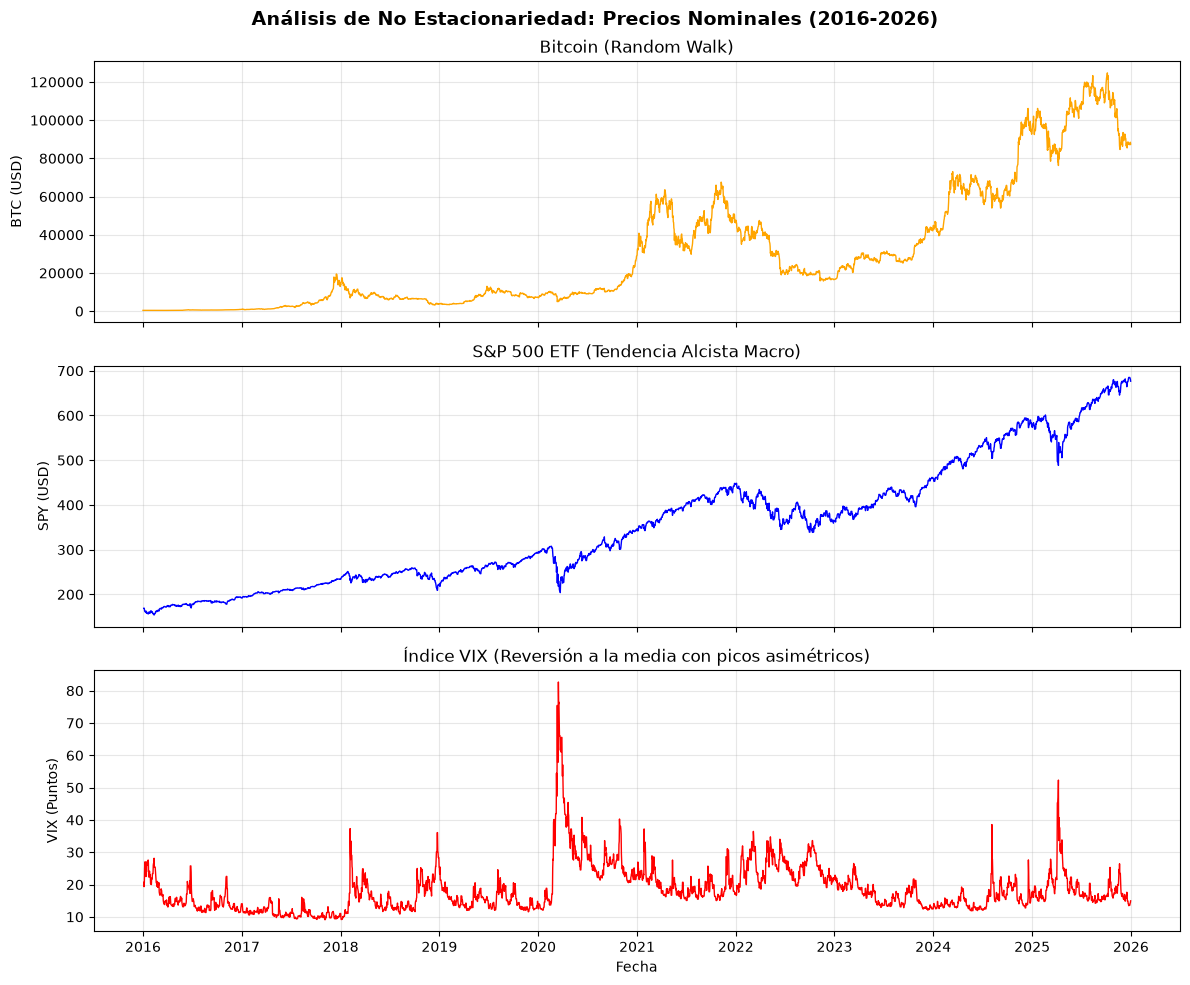

In [13]:
import matplotlib.pyplot as plt

def plot_non_stationarity(df_raw):
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    fig.suptitle('Análisis de No Estacionariedad: Precios Nominales (2016-2026)', fontsize=14, fontweight='bold')
    
    # BTC
    axes[0].plot(df_raw.index, df_raw['BTC_Close'], color='orange', linewidth=1)
    axes[0].set_ylabel('BTC (USD)')
    axes[0].set_title('Bitcoin (Random Walk)')
    axes[0].grid(True, alpha=0.3)
    
    # SPY
    axes[1].plot(df_raw.index, df_raw['SPY_Close'], color='blue', linewidth=1)
    axes[1].set_ylabel('SPY (USD)')
    axes[1].set_title('S&P 500 ETF (Tendencia Alcista Macro)')
    axes[1].grid(True, alpha=0.3)
    
    # VIX
    axes[2].plot(df_raw.index, df_raw['VIX_Close'], color='red', linewidth=1)
    axes[2].set_ylabel('VIX (Puntos)')
    axes[2].set_title('Índice VIX (Reversión a la media con picos asimétricos)')
    axes[2].grid(True, alpha=0.3)
    
    plt.xlabel('Fecha')
    plt.tight_layout()
    plt.show()

plot_non_stationarity(df_raw)

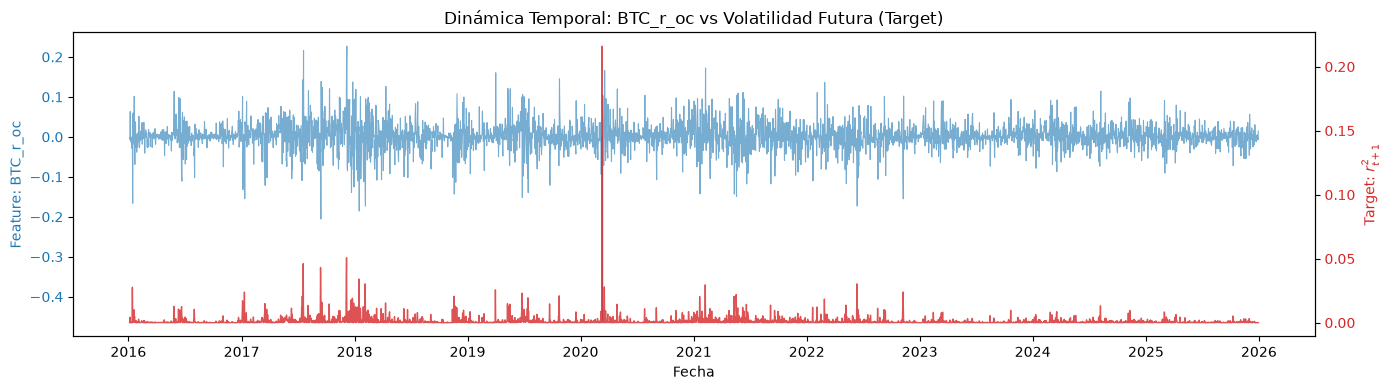

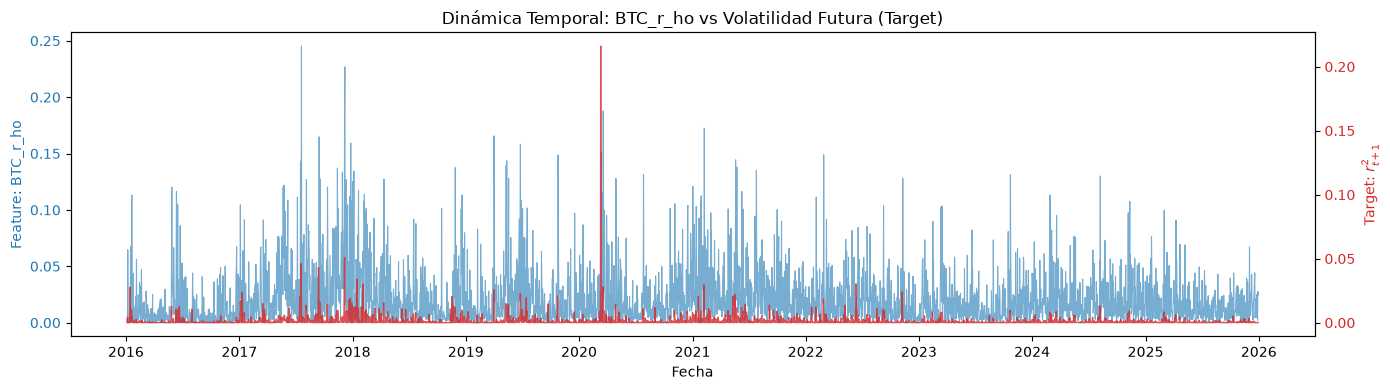

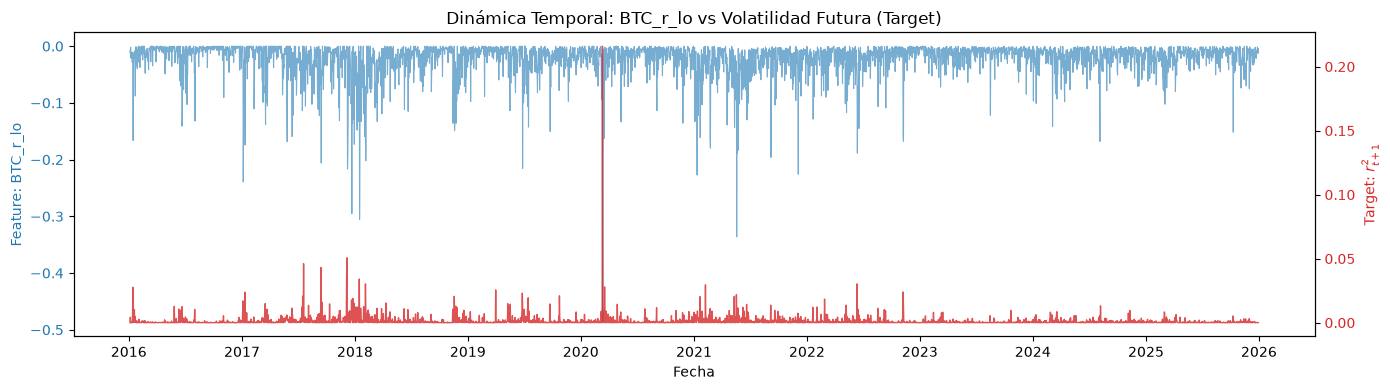

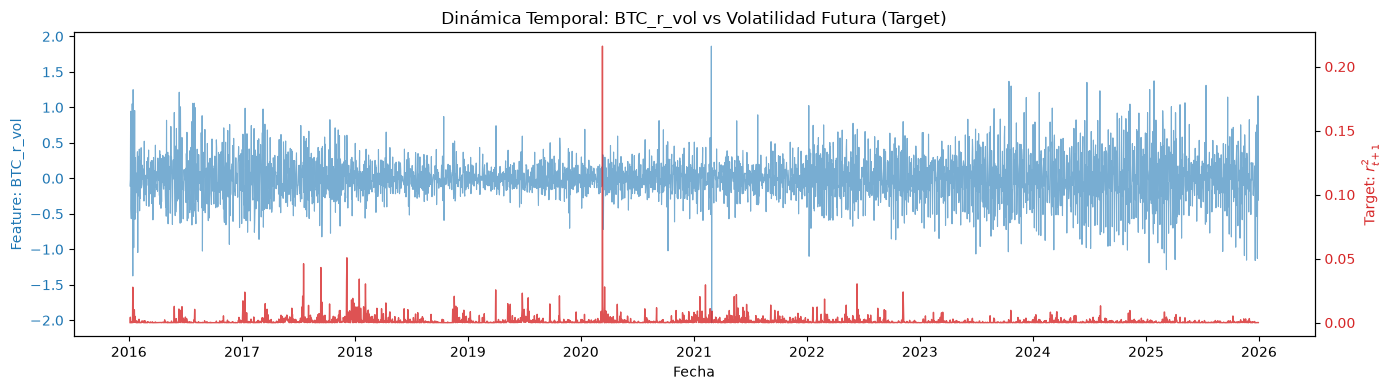

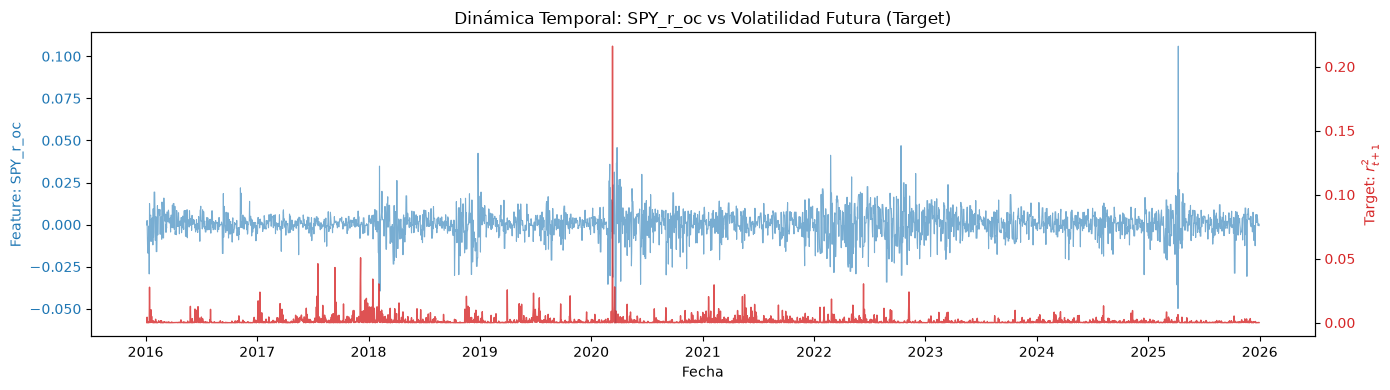

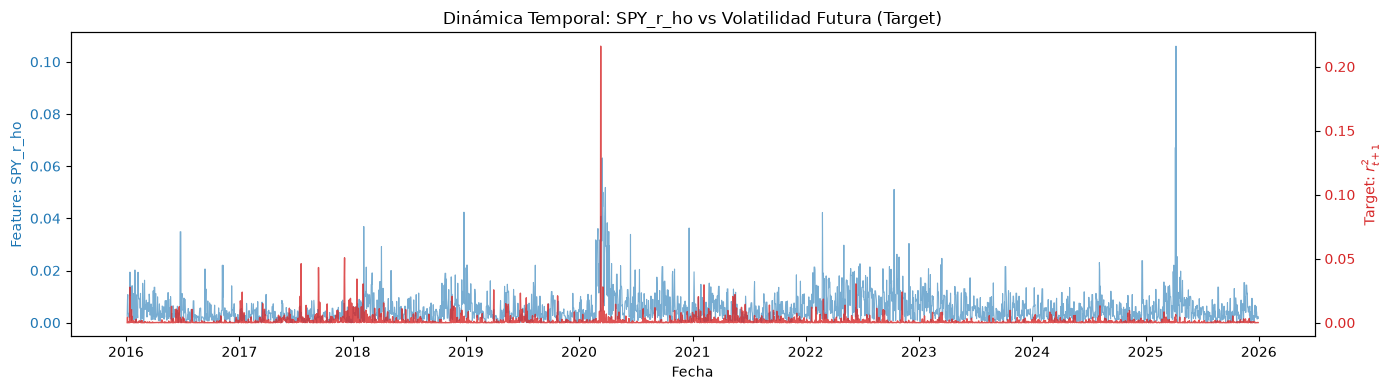

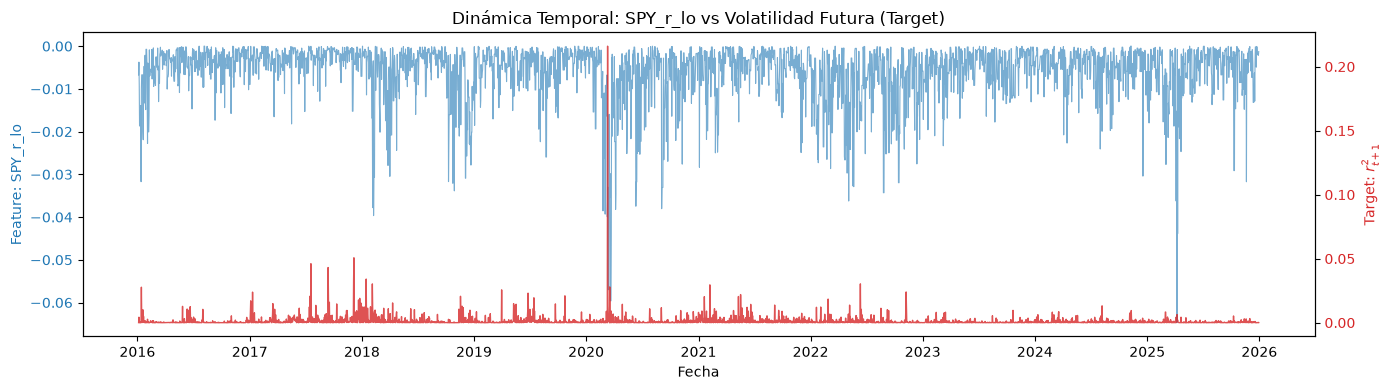

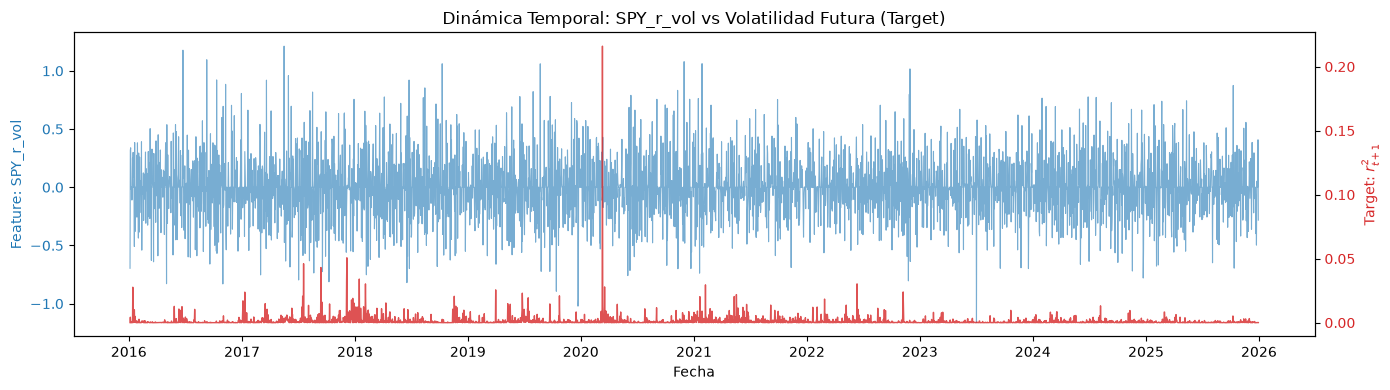

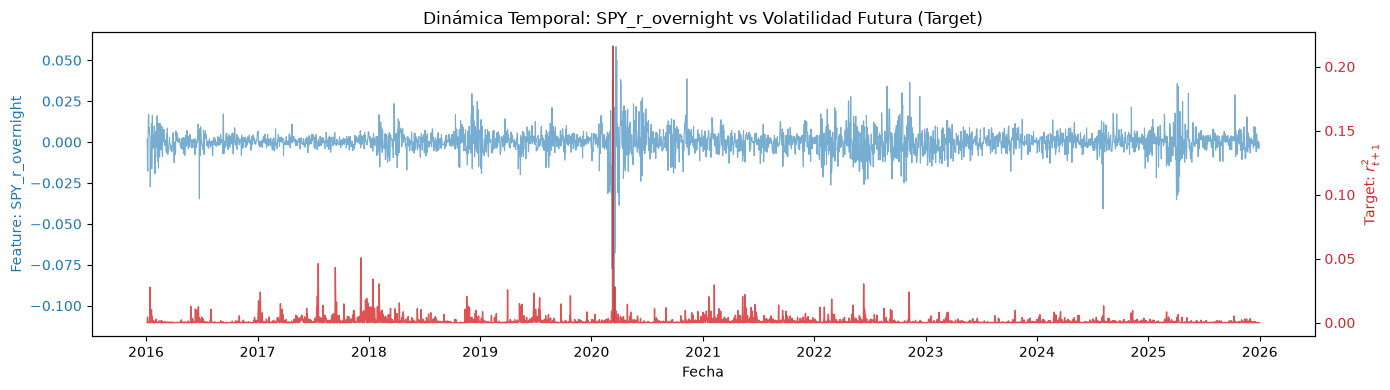

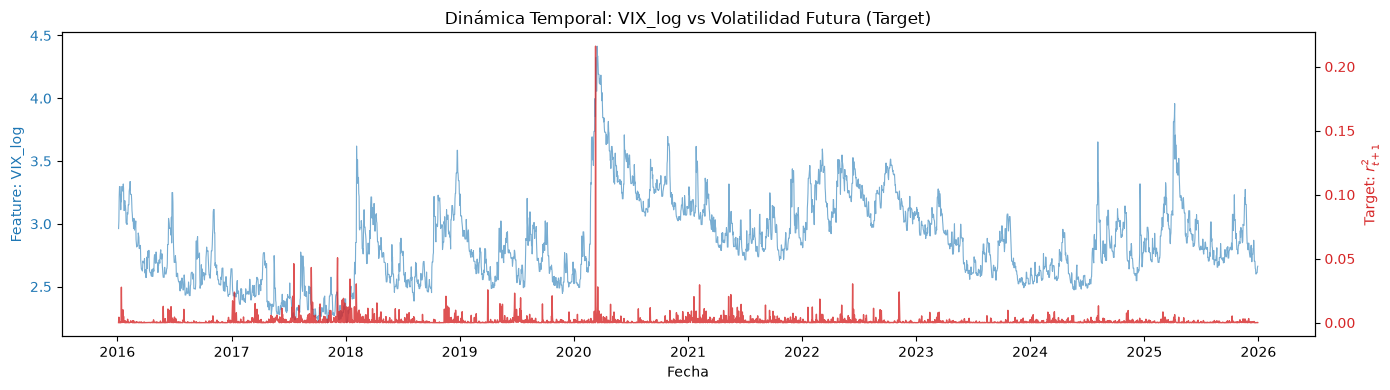

In [14]:
def plot_features_vs_target(df_processed):
    # Lista de features (excluyendo el target)
    features = [col for col in df_processed.columns if col != 'target_r2_t1']
    
    # Para no saturar la salida, podés limitar el ploteo a un subconjunto temporal (ej. 1 año)
    # df_subset = df_processed.loc['2020-01-01':'2020-12-31']
    df_subset = df_processed # Usar todo el dataset
    
    for feature in features:
        fig, ax1 = plt.subplots(figsize=(14, 4))
        
        # Eje Y principal: Feature
        color_feat = 'tab:blue'
        ax1.set_xlabel('Fecha')
        ax1.set_ylabel(f'Feature: {feature}', color=color_feat)
        ax1.plot(df_subset.index, df_subset[feature], color=color_feat, alpha=0.6, linewidth=0.8)
        ax1.tick_params(axis='y', labelcolor=color_feat)
        
        # Eje Y secundario: Target (Varianza Condicional)
        ax2 = ax1.twinx()  
        color_tgt = 'tab:red'
        ax2.set_ylabel('Target: $r_{t+1}^2$', color=color_tgt)
        ax2.plot(df_subset.index, df_subset['target_r2_t1'], color=color_tgt, alpha=0.8, linewidth=1)
        ax2.tick_params(axis='y', labelcolor=color_tgt)
        
        plt.title(f'Dinámica Temporal: {feature} vs Volatilidad Futura (Target)')
        fig.tight_layout()
        plt.show()

plot_features_vs_target(df_processed)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import wandb
import copy
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import RobustScaler

# 1. Función de Pérdida QLIKE
class QLIKELoss(nn.Module):
    def __init__(self, eps=1e-6):
        super(QLIKELoss, self).__init__()
        self.eps = eps

    def forward(self, h_pred, y_true):
        hat_sigma2 = torch.exp(h_pred)
        hat_sigma2 = torch.clamp(hat_sigma2, min=self.eps)
        y_true = torch.clamp(y_true, min=self.eps)
        ratio = y_true / hat_sigma2
        loss = ratio - torch.log(ratio) - 1.0
        return torch.mean(loss)

# 2. Generador de Secuencias
def create_sequences(features, target, timesteps):
    X, y = [], []
    for i in range(len(features) - timesteps):
        X.append(features[i:(i + timesteps)])
        y.append(target[i + timesteps - 1]) 
    return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(y), dtype=torch.float32)

# 3. Entrenamiento por Fold 
def train_fold(model, train_loader, val_loader, optimizer, criterion, epochs, fold_idx):
    best_val_loss = float('inf')
    best_model_state = None
    history = {'train_loss': [], 'val_loss': []}
    
    for epoch in range(epochs):
        model.train()
        train_loss_epoch = 0.0
        
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            h_pred = model(X_batch).squeeze()
            loss = criterion(h_pred, y_batch)
            loss.backward()
            
            
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            
            optimizer.step()
            train_loss_epoch += loss.item() * X_batch.size(0)
            
        train_loss_epoch /= len(train_loader.dataset)
        
        model.eval()
        val_loss_epoch = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                h_pred = model(X_batch).squeeze()
                loss = criterion(h_pred, y_batch)
                val_loss_epoch += loss.item() * X_batch.size(0)
                
        val_loss_epoch /= len(val_loader.dataset)
        
        history['train_loss'].append(train_loss_epoch)
        history['val_loss'].append(val_loss_epoch)
        
        wandb.log({
            f"fold_{fold_idx}_train_loss": train_loss_epoch,
            f"fold_{fold_idx}_val_loss": val_loss_epoch,
            "epoch": epoch
        })
        
        if val_loss_epoch < best_val_loss:
            best_val_loss = val_loss_epoch
            best_model_state = copy.deepcopy(model.state_dict())
            
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    return best_val_loss, history

# 4. Orquestador Walk-Forward con Preprocesamiento
def run_walk_forward_sweep(X_raw, y_raw):
    """
    X_raw: Array numpy o DataFrame de features (N_days, N_features)
    y_raw: Array numpy o Series del target (N_days,)
    """
    wandb.init()
    config = wandb.config
    
    # Inferencia dinámica de la dimensión temporal
    total_days = len(X_raw)
    train_window = 3 * 365 
    val_window = 365 
    
    fold_val_losses = []
    
    for start_idx in range(0, total_days - train_window - val_window + 1, val_window):
        fold_idx = start_idx // val_window
        
        train_start, train_end = start_idx, start_idx + train_window
        val_start, val_end = train_end, train_end + val_window
        
        # Particionamiento estricto
        X_train_fold = X_raw[train_start:train_end]
        y_train_fold = y_raw[train_start:train_end]
        X_val_fold = X_raw[val_start:val_end]
        y_val_fold = y_raw[val_start:val_end]
        
        # RobustScaler ajustado ÚNICAMENTE con datos de entrenamiento
        scaler = RobustScaler()
        X_train_scaled = scaler.fit_transform(X_train_fold)
        X_val_scaled = scaler.transform(X_val_fold)
        
        # Conversión de numpy arrays a tensores espaciales (secuencias)
        X_train_seq, y_train_seq = create_sequences(X_train_scaled, y_train_fold, config.timesteps)
        X_val_seq, y_val_seq = create_sequences(X_val_scaled, y_val_fold, config.timesteps)
        
        # Dataloaders (Stateless permite mezclar el train_loader)
        train_dataset = TensorDataset(X_train_seq, y_train_seq)
        val_dataset = TensorDataset(X_val_seq, y_val_seq)
        
        train_loader = DataLoader(train_dataset, batch_size=config.batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=config.batch_size, shuffle=False)
        
        # Inicialización del modelo (Asegúrate de tener implementada la clase TuRedNeuronal)
        # input_size se obtiene dinámicamente de la cantidad de features escalados
        model = TuRedNeuronal(input_size=X_train_scaled.shape[1], 
                              hidden_size=config.hidden_size, 
                              dropout=config.dropout_rate)
        
        criterion = QLIKELoss()
        optimizer = optim.AdamW(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
        
        # Ejecución del bucle de entrenamiento
        best_fold_loss, history = train_fold(model, train_loader, val_loader, optimizer, criterion, epochs=50, fold_idx=fold_idx)
        
        fold_val_losses.append(best_fold_loss)
        
    avg_val_loss = np.mean(fold_val_losses)
    wandb.log({"avg_cross_val_loss": avg_val_loss})

# 5. Sweep Config (Mismo diccionario que definimos anteriormente)
sweep_config = {
    'method': 'bayes', # Optimización Bayesiana para encontrar parámetros rápido
    'metric': {
        'name': 'avg_cross_val_loss',
        'goal': 'minimize'
    },
    'parameters': {
        'learning_rate': {'min': 1e-4, 'max': 1e-2},
        'weight_decay': {'min': 1e-5, 'max': 1e-3},
        'dropout_rate': {'min': 0.3, 'max': 0.5},
        'hidden_size': {'values': [16, 24, 32]},
        'timesteps': {'values': [3, 7, 10, 14]},
        'batch_size': {'values': [16, 32, 64]}
    }
}

# Para ejecutar el sweep:
# sweep_id = wandb.sweep(sweep_config, project="bitcoin-volatility-dl")
# wandb.agent(sweep_id, run_walk_forward_sweep, count=20)